In [1]:
!pip install ydata-profiling
!pip install optuna

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
## lo básico
import pandas as pd
import numpy as np

## visualización
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

## pre procesado
from sklearn.model_selection import train_test_split
from ydata_profiling import ProfileReport
from sklearn.preprocessing import LabelEncoder

## modelado
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

## métricas
from pandas.plotting import scatter_matrix
from sklearn.metrics import accuracy_score, auc, confusion_matrix, f1_score, precision_score, recall_score, roc_curve
from sklearn.metrics import classification_report

## mejora de modelos
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_val_score,StratifiedKFold
import optuna

## automatización
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [4]:
df_bank=pd.read_csv('/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/1.ejercicio_banco/bank-full.csv', sep=';')

## 1 Análisis exploratorio

In [5]:
df_bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
df_bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [7]:
df_bank.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
df_bank.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [9]:
for i in df_bank.columns:
    print(i)
    print(df_bank[i].value_counts())

age
age
32    2085
31    1996
33    1972
34    1930
35    1894
      ... 
95       2
93       2
92       2
88       2
94       1
Name: count, Length: 77, dtype: int64
job
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64
marital
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64
education
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64
default
default
no     44396
yes      815
Name: count, dtype: int64
balance
balance
0        3514
1         195
2         156
4         139
3         134
         ... 
14204       1
8205        1
9710        1
7038        1
4416        1
Name: count, Length: 7168, dtype: int64
housing
housing
yes    25130
no     200

In [10]:
df_bank.shape

(45211, 17)

In [11]:
df_bank.y.value_counts()

,count
y,
no,39922
yes,5289


In [12]:
df_bank.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


## 2. Conversión a numérica

In [13]:
lista_numericas=['age','balance','duration','day','pdays','previous','campaign']

In [14]:
lista_categoricas=['job','marital','education','contact','month','poutcome']

In [15]:
categoricas_binarias = ['default','housing','loan','y']

In [16]:
## Cambiamos las variables binarias a si/no

for j in categoricas_binarias:
    df_bank[j] = [0 if x == 'no' else 1 for x in df_bank[j]]

In [17]:
## Transformamos las variables a dummies

for k in lista_categoricas:
    dummies = pd.get_dummies(df_bank[k],prefix=k)
    df_bank = pd.concat([df_bank, dummies], axis=1)

### ¿Qué pasa si....

- Tenemos muchas categorías que transformar?
- Tenemos una distribución no uniforme de las categorías?
- Las transformación a dummies no funciona / no tenemos problemas de regresión?
  
https://github.com/solegalli/Python-Feature-Engineering-Cookbook-First-Edition/tree/master/ch03-categorical-encoding

# MÉTODOS ORDENADOS DE MEJOR A PEOR:

###*   Si hay pocas categorías:
*   Dummies

###*   Si hay muchas categorías:
*   Agrupación: agrupando categorías mediante la lógica o agrupando valores poco frecuentes en una sola categoría "valores_raros".
*   Frecuencia: comprobando anteriormente que no haya valores iguales.
*   Target Mean: comprobando posteriormente si no hay sobreajuste mediante la validación cruzada.
*   LabelEncoder




### Transformación a número ordinal

## Método 1

In [18]:
## Los convertimos "a mano". Eficaz con variables tipo month

df_bank['month'].replace(('jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'),
                          (1,2,3,4,5,6,7,8,9,10,11,12),inplace=True)

df_bank['education'].replace(('primary','secondary','tertiary','unknown'),
                              (1,2,3,4),inplace=True)

df_bank['marital'].replace(('married','single','divorced'),
                            (1,2,3),inplace=True)

df_bank['contact'].replace(('cellular','unknown','telephone'),
                            (1,2,3),inplace=True)

df_bank['poutcome'].replace(('failure','unknown','other','success'),
                            (1,2,3,4),inplace=True)

/tmp/ipykernel_23119/335336259.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_bank['month'].replace(('jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'),
/tmp/ipykernel_23119/335336259.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_bank['month'].replace(('jan','f

## Método 2

In [19]:
df_bank.job.unique()

array(['management', 'technician', 'entrepreneur', 'blue-collar',
       'unknown', 'retired', 'admin.', 'services', 'self-employed',
       'unemployed', 'housemaid', 'student'], dtype=object)

In [20]:
df_bank.job

,job
0,management
1,technician
2,entrepreneur
3,blue-collar
4,unknown
...,...
45206,technician
45207,retired
45208,retired
45209,blue-collar


In [21]:
## Convertimos los valores desde 0 hasta n-1 de manera alfabética

le = LabelEncoder()
le.fit(df_bank.job.unique())
print(le.classes_)
print(le.transform(df_bank.job))

['admin.' 'blue-collar' 'entrepreneur' 'housemaid' 'management' 'retired'
 'self-employed' 'services' 'student' 'technician' 'unemployed' 'unknown']
[4 9 2 ... 5 1 2]


In [22]:
for k in lista_categoricas:
    le = LabelEncoder()
    df_bank[k + "2"] = le.fit_transform(df_bank[k])

### Método 3

In [23]:
## Agrupación de valores raros

df_bank["job"].value_counts(normalize=True)

,proportion
job,
blue-collar,0.215257
management,0.209197
technician,0.168034
admin.,0.114375
services,0.091880
retired,0.050076
self-employed,0.034925
entrepreneur,0.032890
unemployed,0.028820


In [24]:
df_bank["job"].value_counts()

,count
job,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303


In [25]:
list(df_bank["job"].value_counts()[df_bank["job"].value_counts(normalize=True)> 0.05].index)

['blue-collar', 'management', 'technician', 'admin.', 'services', 'retired']

In [26]:
np.where(df_bank["job"].isin(['blue-collar', 'management', 'technician', 'admin.', 'services', 'retired']),
         df_bank["job"], "Rare")

array(['management', 'technician', 'Rare', ..., 'retired', 'blue-collar',
       'Rare'], dtype=object)

### Método 4

In [27]:
## Convertimos los valores a frecuencia (le damos un valor mayor a las clases que más aparecen/más peso tienen). ¡Cuidado los valores iguales!

print(df_bank.job.value_counts())

print(df_bank.job.head())

df_bank.job.map(df_bank.job.value_counts())

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64
0      management
1      technician
2    entrepreneur
3     blue-collar
4         unknown
Name: job, dtype: object


,job
0,9458
1,7597
2,1487
3,9732
4,288
...,...
45206,7597
45207,2264
45208,2264
45209,9732


In [28]:
for k in lista_categoricas:
    df_bank[k] = df_bank[k].map(df_bank[k].value_counts())

### Método 5

In [29]:
### Target mean (se sustituye por la media de la target). Cuidado, puede causar overfitting (sobreajuste)

mean_target = df_bank.groupby('job')['y'].mean()

# Reemplazar categorías por la media
df_bank['job_encoded'] = df_bank['job'].map(mean_target)

print(df_bank[['job', 'job_encoded']])

        job  job_encoded
0      9458     0.137556
1      7597     0.110570
2      1487     0.082717
3      9732     0.072750
4       288     0.118056
...     ...          ...
45206  7597     0.110570
45207  2264     0.227915
45208  2264     0.227915
45209  9732     0.072750
45210  1487     0.082717

[45211 rows x 2 columns]


In [30]:
mean_target

,y
job,
288,0.118056
938,0.286780
1240,0.087903
1303,0.155027
1487,0.082717
1579,0.118429
2264,0.227915
4154,0.088830
5171,0.122027


In [31]:
### hay algún valor más, pero se usan muy poco (transformación binaria...)

In [32]:
corr = abs(df_bank.corr())
corr[['y']].sort_values(by = 'y',ascending = False)

,y
y,1.000000
duration,0.394521
poutcome_success,0.306788
poutcome2,0.213476
poutcome,0.176288
...,...
month_aug,0.008536
job_admin.,0.005637
marital_divorced,0.002772
job_self-employed,0.000855


### 3.Muestreo estratificado

In [33]:
X_train, X_test, y_train, y_test = train_test_split(df_bank.drop('y',axis=1),
                                                    df_bank.y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify = df_bank.y)

### 4.Modelado

In [34]:
model1 = RandomForestClassifier()

In [35]:
model1.fit(X_train,y_train)
y_pred = model1.predict(X_test)

### 5.Métricas

In [36]:
def saca_metricas(y1, y2):
    print('Matriz de Confusión')
    print(confusion_matrix(y1, y2))
    print('Accuracy:', accuracy_score(y1, y2))
    print('Precision:', precision_score(y1, y2))
    print('Recall:', recall_score(y1, y2))
    print('F1 Score:', f1_score(y1, y2))

    # Cálculo de la curva ROC y AUC
    false_positive_rate, recall, _ = roc_curve(y1, y2)
    roc_auc = auc(false_positive_rate, recall)
    print('AUC:', roc_auc)

    # Crear gráfico interactivo con Plotly
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=false_positive_rate, y=recall, mode='lines', name='Curva ROC', line=dict(color='blue')))
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', name='Línea base', line=dict(color='red', dash='dash')))

    fig.update_layout(
        title=f'Curva ROC (AUC = {roc_auc:.2f})',
        xaxis_title='False Positive Rate',
        yaxis_title='Recall',
        template='plotly_white'
    )

    fig.show()

In [37]:
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[7766  219]
 [ 637  421]]
Accuracy: 0.9053411478491651
Precision: 0.6578125
Recall: 0.39792060491493386
F1 Score: 0.4958775029446408
AUC: 0.685247090184455


In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7985
           1       0.66      0.40      0.50      1058

    accuracy                           0.91      9043
   macro avg       0.79      0.69      0.72      9043
weighted avg       0.89      0.91      0.89      9043



In [39]:
def plot_feature_importance(model, X_train):
    feat_importances = pd.DataFrame(model.feature_importances_, index=X_train.columns, columns=["Importance"])
    feat_importances.sort_values(by='Importance', ascending=False, inplace=True)

    fig = px.bar(feat_importances, x=feat_importances.index, y='Importance', title='Feature Importances', labels={'x': 'Features', 'Importance': 'Importance'}, template='plotly_white')
    fig.show()

    return feat_importances

In [40]:
plot_feature_importance(model1, X_train)

,Importance
duration,0.250841
balance,0.083867
age,0.082823
day,0.076879
campaign,0.037112
...,...
job_entrepreneur,0.001860
default,0.001740
job_housemaid,0.001625
month_dec,0.001620


### 6.Feature Engineering

In [41]:
def plot_target_vs_features(var, target, df):
    proporcion = pd.DataFrame()
    proporcion['%'] = df[target].groupby(df[var]).mean() * 100
    proporcion['Conteo'] = df[target].groupby(df[var]).count()
    proporcion = proporcion.round(3)
    proporcion_filtered = proporcion[(proporcion['%'] > 0) & (proporcion['Conteo'] > 10)]

    if len(proporcion_filtered) < 100 and len(proporcion_filtered) > 1:
        fig = px.bar(proporcion_filtered, x=proporcion_filtered.index, y='Conteo', title=f'Distribución de {var}', labels={'x': var, 'Conteo': 'Cantidad'}, template='plotly_white')
        fig.add_trace(go.Scatter(x=proporcion_filtered.index, y=proporcion_filtered['%'], mode='lines+markers', name='%', yaxis='y2', line=dict(color='green')))

        fig.update_layout(
            yaxis2=dict(title='%', overlaying='y', side='right')
        )
    elif len(proporcion_filtered) >= 100:
        df_filtered = df[[var, target]].dropna()
        df_filtered['bin'] = pd.qcut(df_filtered[var], q=20, duplicates='drop')
        bin_means = df_filtered.groupby('bin')[target].mean() * 100
        bin_counts = df_filtered.groupby('bin')[target].count()

        fig = go.Figure()
        fig.add_trace(go.Bar(x=bin_means.index.astype(str), y=bin_counts, name='Conteo', yaxis='y', marker_color='blue'))
        fig.add_trace(go.Scatter(x=bin_means.index.astype(str), y=bin_means, mode='lines+markers', name='%', yaxis='y2', line=dict(color='green')))

        fig.update_layout(
            title=f'Relación entre {var} y {target}',
            xaxis_title=f'Binned {var}',
            yaxis=dict(title='Conteo'),
            yaxis2=dict(title='%', overlaying='y', side='right'),
            template='plotly_white'
        )
    else:
        proporcion_filtered.reset_index(inplace=True)
        fig = px.scatter(proporcion_filtered, x=var, y='%', trendline='ols', title=f'Relación entre {var} y % Depósitos', template='plotly_white')

    fig.show()


In [42]:
for i in df_bank.columns:
    plot_target_vs_features (i, 'y', df_bank)

/tmp/ipykernel_23119/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_23119/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_23119/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_23119/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



/tmp/ipykernel_23119/322798919.py:18: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_23119/322798919.py:19: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



Método 1: ver cómo se comporta cada variable con el porcentaje de contratación

In [43]:
## AGE (realizamos una variable con 3 rangos de edad y 3 variables con esos mismos rangos)
df_bank['age_joven'] = df_bank['age'].apply(lambda x: 1 if x<=35 else 0)
df_bank['age_adulto'] = df_bank['age'].apply(lambda x: 1 if x>35 & x<60 else 0)
df_bank['age_jubilado'] = df_bank['age'].apply(lambda x: 1 if x>60 else 0)
df_bank['age_new'] = df_bank['age'].apply(lambda x: 0 if x<=35 else (1 if x>35 and x<60 else(2)))

In [44]:
## CAMPAIGN (observamos que la mitad de los datos están entre 1 y 2, creamos una nueva clase para el resto)
df_bank['campaign_new'] = df_bank['campaign'].apply(lambda x: 0 if x<=15 else 1)
df_bank['campaign_new2'] = df_bank['campaign'].apply(lambda x: 1 if x==1 else (2 if x==2 else(3)))

## PDAYS (casi todos los datos están en -1 (no contactado), por tanto, transformamos la variable en contactados y no contactados)
df_bank['pdays_new5'] = df_bank['pdays'].apply(lambda x: 0 if x<=0 else (1 if x<7 else(2 if x>=7 and x<14 else(3))))
df_bank['pdays_new'] = df_bank['pdays'].apply(lambda x: 0 if x==-1 else x)
df_bank['pdays_new2'] = df_bank['pdays']//30
df_bank['pdays'] = df_bank['pdays'].apply(lambda x: 0 if x==-1 else x)
df_bank['pdays_new2'] = df_bank['pdays_new2'].apply(lambda x: 0 if x==-1 else x)
df_bank['pdays_new3'] = df_bank['pdays_new2'].apply(lambda x: 0 if x<=0 else x)

## PREVIOUS (al igual que anteriormente, la mayoría no han sido contactados anteriormente, creamos una variable binaria)
df_bank['previous_new'] = df_bank['previous'].apply(lambda x: 0 if x == 0 else 1)
df_bank['previous_new_2'] = df_bank['previous'].apply(lambda x: 0 if x == 0 else 1)

df_bank['previous_new_2'] = df_bank['previous_new_2'].apply(lambda x: 0 if x<=0 else x)

## BALANCE (en este caso, hacemos tramos de la variable)
df_bank['balance_new'] = df_bank['balance'].apply(lambda x: 0 if x<=0 else x)
df_bank['balance_negativo'] = df_bank['balance'].apply(lambda x: 1 if x<=0 else 0)
df_bank['balance_new2'] = df_bank['balance'].apply(lambda x: 0 if x<=100 else (1 if x>100 and x<=500 else(2 if x>500 and x<=2000 else(3 if x>2000 and x<10000 else(4)))))
df_bank['balance'] = df_bank['balance'].apply(lambda x: 0 if x<=0 else x)

## JOB (podemos hacer una variable de empleado y no empleado)
df_bank['job_new'] = df_bank['job'].apply(lambda x: 1 if x==5 or x ==8 or x==10  else 0)

Método 2: asignar tramos

In [45]:
def tramos(varib,varib_destino,tamanio,maximo,df):
    df[varib_destino]=np.where(df[varib]==0,-1,(df[varib]//tamanio)*tamanio)
    df[varib_destino]=np.where(df[varib_destino]>=maximo,maximo,df[varib_destino])

In [46]:
tramos('duration','duration_new',5,4900,df_bank)
df_bank['duration_new'] = df_bank['duration_new'].apply(lambda x: 0 if x<=0 else x)
df_bank['duration_new2'] = df_bank['duration_new']//60

In [47]:
tramos('pdays_new2','pdays_new3',2,14,df_bank)
tramos('previous','previous_new_2',2,10,df_bank)
tramos('day','day_new',15,31,df_bank)
tramos('balance','balance_new',500,10000,df_bank)

Método 3: crear nuevos estadísticos

In [48]:
features = ['duration' , 'age']

In [49]:
df_bank["mean_duration-age"] = df_bank[features].mean(axis=1)

In [50]:
math_func = ["sum", "prod", "mean", "std", "max", "min"]

In [51]:
df_bank[features].agg(math_func, axis="columns")

,sum,prod,mean,std,max,min
0,319.0,15138.0,159.5,143.542677,261.0,58.0
1,195.0,6644.0,97.5,75.660426,151.0,44.0
2,109.0,2508.0,54.5,30.405592,76.0,33.0
3,139.0,4324.0,69.5,31.819805,92.0,47.0
4,231.0,6534.0,115.5,116.672619,198.0,33.0
...,...,...,...,...,...,...
45206,1028.0,49827.0,514.0,654.780879,977.0,51.0
45207,527.0,32376.0,263.5,272.236111,456.0,71.0
45208,1199.0,81144.0,599.5,745.997654,1127.0,72.0
45209,565.0,28956.0,282.5,318.905158,508.0,57.0


### 7.Transformación de variables continuas

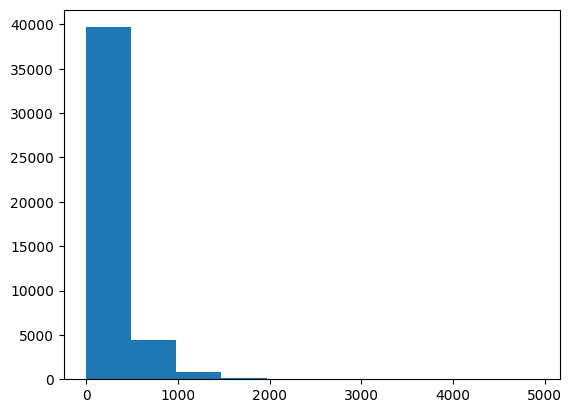

In [52]:
plt.hist(df_bank['duration'])
plt.show()

Método 1: YeoJohnson

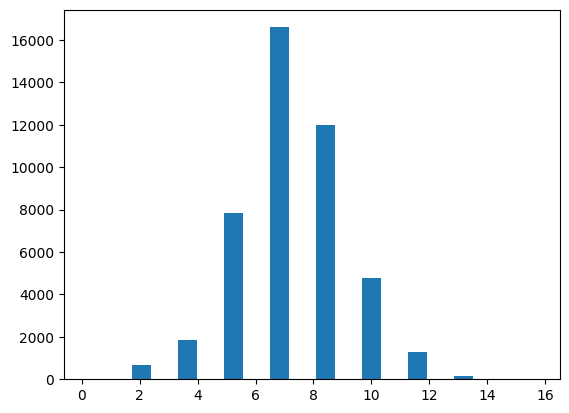

In [53]:
from scipy.stats import yeojohnson

plt.hist(yeojohnson(df_bank['duration']))
plt.show()

Método 2: BoxCox

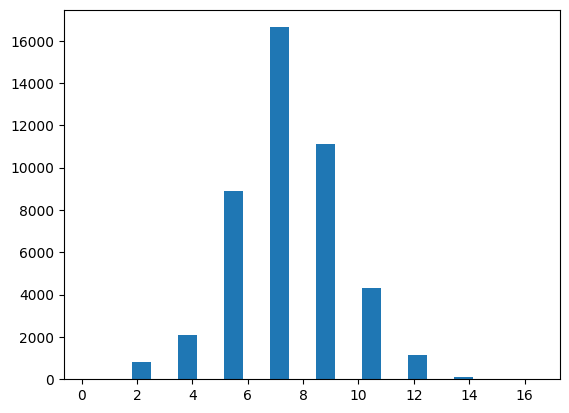

In [54]:
import numpy as np
from scipy.stats import boxcox

plt.hist(boxcox(df_bank[df_bank['duration']>0]['duration']))
plt.show()

Método 3: normalizar las variables

In [55]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
prueba_escalado = sc.fit_transform(df_bank)

In [56]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
prueba_escalado = sc.fit_transform(df_bank)

Método 4: trameo a través de sklearn

In [57]:
from sklearn.preprocessing import KBinsDiscretizer
est = KBinsDiscretizer(
    n_bins=20, encode='ordinal', strategy='uniform'
)
est.fit_transform(df_bank[['age']])


array([[10.],
       [ 6.],
       [ 3.],
       ...,
       [14.],
       [10.],
       [ 4.]])

In [58]:
## hay más métodos: escala logarítmica, clustering, árboles de decisión, binarizer...

In [59]:
corr = abs(df_bank.corr())
corr[['y']].sort_values(by = 'y',ascending = False)

,y
y,1.000000
mean_duration-age,0.395298
duration_new,0.394555
duration,0.394521
duration_new2,0.393241
...,...
job_admin.,0.005637
marital_divorced,0.002772
job_self-employed,0.000855
job_unknown,0.000267


### 8.Muestreo estratificado

In [60]:
X_train, X_test, y_train, y_test = train_test_split(df_bank.drop('y',axis=1),
                                                    df_bank.y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify = df_bank.y)

### 9.Selección de variables

Método 1

In [61]:
list(corr[['y']].sort_values(by = 'y',ascending = False).index)

['y',
 'mean_duration-age',
 'duration_new',
 'duration',
 'duration_new2',
 'poutcome_success',
 'poutcome2',
 'poutcome',
 'pdays_new5',
 'previous_new',
 'poutcome_unknown',
 'month',
 'age_jubilado',
 'contact_unknown',
 'previous_new_2',
 'housing',
 'job_encoded',
 'contact_cellular',
 'month_mar',
 'month_oct',
 'month_sep',
 'contact',
 'pdays_new3',
 'pdays',
 'pdays_new',
 'month_may',
 'pdays_new2',
 'contact2',
 'balance_new2',
 'previous',
 'job_retired',
 'campaign_new2',
 'job_student',
 'month_dec',
 'campaign',
 'job_blue-collar',
 'loan',
 'education_tertiary',
 'education2',
 'balance_negativo',
 'month_apr',
 'balance_new',
 'marital_single',
 'marital_married',
 'job',
 'balance',
 'marital',
 'marital2',
 'job2',
 'education_primary',
 'month_feb',
 'education_secondary',
 'month_jul',
 'job_management',
 'poutcome_other',
 'campaign_new',
 'age_joven',
 'day',
 'job_services',
 'age',
 'age_new',
 'default',
 'day_new',
 'job_unemployed',
 'job_entrepreneur',
 'm

In [62]:
lista_final = [
 'mean_duration-age',
 'duration_new',
 'poutcome_success',
 'pdays_new5',
 'previous_new',
 'poutcome_unknown',
 'month',
 'age_jubilado',
 'contact_unknown',
 'housing',
 'job_encoded',
 'contact_cellular',
 'balance_new2',
 'job_retired',
 'job_student',
 'marital_single',
 'marital_married',
 'education_primary']

In [63]:
model = RandomForestClassifier().fit(X_train[lista_final],y_train)
y_pred = model.predict(X_test[lista_final])

In [64]:
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[7653  332]
 [ 588  470]]
Accuracy: 0.8982638504920933
Precision: 0.5860349127182045
Recall: 0.444234404536862
F1 Score: 0.5053763440860215
AUC: 0.7013282229321756


Método 2

In [65]:
model = RandomForestClassifier().fit(X_train,y_train)
y_pred = model.predict(X_test)

In [66]:
feature_importances = plot_feature_importance(model, X_train)

In [67]:
feature_importances[:30]

,Importance
duration,0.092620
duration_new,0.090399
mean_duration-age,0.085072
duration_new2,0.051644
age,0.044611
day,0.044289
balance,0.042752
month,0.039325
poutcome2,0.027060
balance_new,0.023186


In [68]:
feature_importances.index

Index(['duration', 'duration_new', 'mean_duration-age', 'duration_new2', 'age',
       'day', 'balance', 'month', 'poutcome2', 'balance_new', 'month2',
       'poutcome', 'poutcome_success', 'campaign', 'job_encoded', 'pdays',
       'job', 'pdays_new', 'job2', 'balance_new2', 'housing', 'campaign_new2',
       'day_new', 'pdays_new2', 'education2', 'age_new', 'education',
       'month_jun', 'pdays_new3', 'previous_new_2', 'previous', 'marital',
       'marital2', 'age_jubilado', 'month_apr', 'age_adulto',
       'education_tertiary', 'loan', 'marital_married', 'education_secondary',
       'age_joven', 'month_mar', 'month_may', 'marital_single', 'contact2',
       'contact_unknown', 'contact_cellular', 'contact', 'job_management',
       'month_oct', 'job_technician', 'month_aug', 'poutcome_failure',
       'month_jul', 'month_nov', 'job_admin.', 'balance_negativo', 'month_feb',
       'marital_divorced', 'education_primary', 'job_blue-collar',
       'job_services', 'month_sep', 'ed

In [69]:
lista_final2 = ['duration_new', 'mean_duration-age', 'age',
       'day', 'balance', 'month', 'poutcome', 'campaign', 'pdays', 'job_encoded',
       'housing', 'education2']

In [70]:
model = RandomForestClassifier().fit(X_train[lista_final2],y_train)
y_pred = model.predict(X_test[lista_final2])

In [71]:
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[7735  250]
 [ 606  452]]
Accuracy: 0.9053411478491651
Precision: 0.6438746438746439
Recall: 0.42722117202268434
F1 Score: 0.5136363636363637
AUC: 0.6979562341015112


Método 3: SelectKBest

In [72]:
selection = SelectKBest(k = 20)
feature_selection = selection.fit_transform(df_bank.drop('y', axis=1), df_bank['y'])

variables = list(np.asarray(list(df_bank.drop('y', axis=1)))[selection.get_support()])
variables.sort()
print(variables)

[np.str_('age_jubilado'), np.str_('contact_cellular'), np.str_('contact_unknown'), np.str_('duration'), np.str_('duration_new'), np.str_('duration_new2'), np.str_('housing'), np.str_('job_encoded'), np.str_('mean_duration-age'), np.str_('month'), np.str_('month_mar'), np.str_('month_oct'), np.str_('month_sep'), np.str_('pdays_new5'), np.str_('poutcome'), np.str_('poutcome2'), np.str_('poutcome_success'), np.str_('poutcome_unknown'), np.str_('previous_new'), np.str_('previous_new_2')]


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning:

Features [76] are constant.

/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning:

invalid value encountered in divide



Método 4: selección por varianza

In [73]:
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.6)
selector.fit_transform(df_bank)

array([[5.8000e+01, 9.4580e+03, 2.7214e+04, ..., 4.0000e+00, 0.0000e+00,
        1.5950e+02],
       [4.4000e+01, 7.5970e+03, 1.2790e+04, ..., 2.0000e+00, 0.0000e+00,
        9.7500e+01],
       [3.3000e+01, 1.4870e+03, 2.7214e+04, ..., 1.0000e+00, 0.0000e+00,
        5.4500e+01],
       ...,
       [7.2000e+01, 2.2640e+03, 2.7214e+04, ..., 1.8000e+01, 1.5000e+01,
        5.9950e+02],
       [5.7000e+01, 9.7320e+03, 2.7214e+04, ..., 8.0000e+00, 1.5000e+01,
        2.8250e+02],
       [3.7000e+01, 1.4870e+03, 2.7214e+04, ..., 6.0000e+00, 1.5000e+01,
        1.9900e+02]])

In [74]:
selector.get_feature_names_out()

array(['age', 'job', 'marital', 'education', 'balance', 'contact', 'day',
       'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome',
       'job2', 'month2', 'campaign_new2', 'pdays_new5', 'pdays_new',
       'pdays_new2', 'pdays_new3', 'previous_new_2', 'balance_new',
       'balance_new2', 'duration_new', 'duration_new2', 'day_new',
       'mean_duration-age'], dtype=object)

In [75]:
## hay más métodos: stepwise...

### 10.Tuneo de hiperparámetros

In [76]:
grid_param = {
    'n_estimators': [50,200],
    'max_depth': [22,24]
}

In [77]:
## cuidado, tarda mucho

model_grid = GridSearchCV(   estimator=model,
                             param_grid=grid_param,
                             scoring='f1',
                             cv=5,
                             n_jobs=-1)

In [78]:
model_grid.fit(X_train[lista_final2], y_train)
print(model_grid.best_params_)
print(model_grid.best_score_)

{'max_depth': 22, 'n_estimators': 200}
0.512925925573054


In [79]:
model3 = RandomForestClassifier(max_depth=22, n_estimators=50).fit(X_train[lista_final2],y_train)
y_pred = model3.predict(X_test[lista_final2])

In [80]:
model3.predict(X_test[lista_final2])

array([0, 0, 0, ..., 0, 0, 0])

In [81]:
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[7701  284]
 [ 607  451]]
Accuracy: 0.9014707508570164
Precision: 0.6136054421768707
Recall: 0.42627599243856334
F1 Score: 0.5030674846625767
AUC: 0.6953546524497137


In [82]:
y_train.value_counts()

,count
y,
0,31937
1,4231


In [83]:
## cuidado, tarda mucho

study = optuna.create_study(direction="maximize")

for _ in range(20):  # número de trials

    trial = study.ask()

    n_estimators = trial.suggest_int("n_estimators", 100, 500)
    max_depth = trial.suggest_int("max_depth", 3, 20)

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=42,
        n_jobs=-1
    )

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    study.tell(trial, np.mean(scores))


[I 2026-03-13 19:12:37,126] A new study created in memory with name: no-name-faf07f2b-a460-4e5b-8c16-d79b7c7cf84d


In [84]:
study.best_params


{'n_estimators': 496, 'max_depth': 17}

### 11.Balanceo de datos

In [85]:
df_bank['y'].value_counts()

,count
y,
0,39922
1,5289


In [86]:
X_train = X_train[lista_final2]
X_test = X_test[lista_final2]

In [87]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train==1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train==0)))

sm = SMOTE(random_state=2,sampling_strategy=0.6)

X_train_res, y_train_res = sm.fit_resample(X_train, y_train.ravel())

print('After OverSampling, the shape of train_X: {}'.format(X_train_res.shape))
print('After OverSampling, the shape of train_y: {} \n'.format(y_train_res.shape))

print("After OverSampling, counts of label '1': {}".format(sum(y_train_res==1)))
print("After OverSampling, counts of label '0': {}".format(sum(y_train_res==0)))

Before OverSampling, counts of label '1': 4231
Before OverSampling, counts of label '0': 31937 

After OverSampling, the shape of train_X: (51099, 12)
After OverSampling, the shape of train_y: (51099,) 

After OverSampling, counts of label '1': 19162
After OverSampling, counts of label '0': 31937


/tmp/ipykernel_23119/4049502231.py:6: FutureWarning:

Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.



In [88]:
model4 = RandomForestClassifier(class_weight='balanced').fit(X_train_res,y_train_res)
y_pred= model4.predict(X_test)

In [89]:
saca_metricas(y_test, y_pred)

Matriz de Confusión
[[7419  566]
 [ 415  643]]
Accuracy: 0.8915183014486343
Precision: 0.5318444995864351
Recall: 0.6077504725897921
F1 Score: 0.5672695191883547
AUC: 0.7684337835710388


In [90]:
y_test.value_counts()

,count
y,
0,7985
1,1058


In [91]:
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5)

In [92]:
results = cross_val_score(estimator=model4, X=X_train_res, y=y_train_res, cv=skf)

In [93]:
results

array([0.83082192, 0.92778865, 0.93258317, 0.93669276, 0.934338  ])

In [94]:
print(results.mean())

0.9124448989823453


In [95]:
print(results.std())

0.04091590942294371


### 12.Automatización

- SimpleImputer: nos permite imputar datos en base a diferentes estrategias
- OneHotEncoder: hace lo mismo que el pd.get_dummies pero se ejecuta como el LabelEncoder
- ColumnTransformer: permite hacer transformaciones (las que queramos, ejemplo, las del SimpleImputer) por columna
- Pipeline: permite ejecutar un flujo en el orden que digamos

In [96]:
data = pd.read_csv('/content/drive/MyDrive/Machine Learning/3. José Ángel Carballo/1.ejercicio_banco/bank-full.csv', sep=';')


X = data.drop(columns=["y"])
y = data["y"].map({'no': 0, 'yes': 1})


num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Preprocesamiento de datos
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# Definir modelos y sus hiperparámetros
models = {
    'DecisionTree': DecisionTreeClassifier(),
    'RandomForest': RandomForestClassifier()
}

param_grid = {
    'DecisionTree': {
        'classifier__max_depth': [3, 5, 10, None],
    },
    'RandomForest': {
        'classifier__n_estimators': [50, 100, 200],
    }
}


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

# Realizar GridSearch para cada modelo
best_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    grid_search = GridSearchCV(pipeline, param_grid[name], cv=5, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    print(f"Mejor modelo para {name}: {grid_search.best_params_}, Mejor Score: {grid_search.best_score_}")

# Evaluar en datos de prueba
for name, model in best_models.items():
    test_score = model.score(X_test, y_test)
    print(f"Precisión en test para {name}: {test_score}")


Mejor modelo para DecisionTree: {'classifier__max_depth': 5}, Mejor Score: 0.9023446663242585
Mejor modelo para RandomForest: {'classifier__n_estimators': 100}, Mejor Score: 0.9061325114926323
Precisión en test para DecisionTree: 0.8994802609753401
Precisión en test para RandomForest: 0.9055623133915736


In [97]:
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'day',
                                                   'duration', 'campaign',
                                                   'pdays', 'previous']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('classifier', RandomForestClassifier())])

### 13. Scripts/entregables

In [98]:
import pickle

pkl_filename = "modelo.pkl"

with open(pkl_filename, 'wb') as file:

    pickle.dump(model, file)


In [99]:
# Load from file
import pickle

pkl_filename = "modelo.pkl"

with open(pkl_filename, 'rb') as file:

    model35 = pickle.load(file)

In [100]:
model35

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'day',
                                                   'duration', 'campaign',
                                                   'pdays', 'previous']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'poutcome'])])),
                ('classifier', RandomForestClassifier())])

In [101]:
y_pred = model.predict(X_test)

In [102]:
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [103]:
X_test.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,347,2,-1,0,unknown
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,203,2,-1,0,unknown
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,228,5,-1,0,unknown
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,153,4,-1,0,unknown
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,61,1,-1,0,unknown


In [104]:
len(y_pred)

9043

In [105]:
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [106]:
model.predict_proba(X_test)[:,0]

array([1.  , 1.  , 0.98, ..., 0.95, 0.86, 0.95])

In [107]:
model.predict_proba(X_test)[:,1]

array([0.  , 0.  , 0.02, ..., 0.05, 0.14, 0.05])

In [108]:
X_test['probabilidad'] = model.predict_proba(X_test)[:,1]

In [109]:
X_test.sort_values(by = 'probabilidad', ascending = False)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,probabilidad
43005,60,retired,married,secondary,no,523,no,no,cellular,11,feb,467,1,182,3,success,0.92
44735,36,management,married,tertiary,no,2161,no,no,cellular,8,sep,708,2,183,5,success,0.92
43731,72,retired,married,secondary,no,5715,no,no,cellular,17,may,1114,1,181,2,success,0.91
43033,48,unemployed,married,secondary,no,926,no,no,cellular,15,feb,382,4,185,6,success,0.91
43122,20,student,single,secondary,no,215,no,no,cellular,24,feb,175,1,92,6,success,0.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11883,48,blue-collar,married,secondary,no,10724,no,no,unknown,20,jun,238,3,-1,0,unknown,0.00
3604,31,unemployed,single,primary,no,0,yes,no,unknown,15,may,24,18,-1,0,unknown,0.00
35284,55,blue-collar,divorced,secondary,no,-152,yes,no,cellular,7,may,36,3,-1,0,unknown,0.00
22375,38,management,married,tertiary,no,546,no,no,cellular,22,aug,82,2,-1,0,unknown,0.00
